## C1 - WEEK 3

In [12]:
import sys
sys.path.append("..")  # repo root, for utils/
#needed libraries

import os
import re
import cv2
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## TASK 1: Filter noise with linear or non-linear filters

In [13]:
#qsd1 path and results folder
qsd1_path = "./data/qsd1_w3"
results_dir = "./results"
os.makedirs(results_dir, exist_ok=True)

def read_image(img_path):
    image = cv2.imread(img_path)
    if image is None:
        raise IOError(f"Could not read {img_path}")
    return image

#sort files in natural order 
def return_number(string):
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', string)]

qsd1_files = [f for f in os.listdir(qsd1_path) if f.lower().endswith(".jpg")]
qsd1_files.sort(key=return_number)

#query images (some noisy) and their clean version (same file name, non_augmented/ folder)
qsd1_imgs = [read_image(os.path.join(qsd1_path, f)) for f in qsd1_files]
qsd1_clean = [read_image(os.path.join(qsd1_path, "non_augmented", f)) for f in qsd1_files]

#real labels: only used at the end to check the result
with open(os.path.join(qsd1_path, "augmentations.pkl"), "rb") as f:
    qsd1_augs = pickle.load(f)
qsd1_really_noisy = np.array(["Noise" in a for a in qsd1_augs])

First we have to decide which images are noisy and which are not

In [14]:
# Additive noise (a small random value added to each pixel)

LAPLACIAN_DIFF = np.array([[1, -2, 1],
                           [-2, 4, -2],
                           [1, -2, 1]], dtype=np.float64)

def additive_noise(img):
    sigmas = []
    for c in range(img.shape[2]):
        residual = cv2.filter2D(img[..., c].astype(np.float64), -1, LAPLACIAN_DIFF)[1:-1, 1:-1]   #drop the border (padding)
        sigmas.append(np.median(np.abs(residual)) / (0.6745 * 6))
    return np.mean(sigmas)

# Impulse noise (a pixel is replaced by a random value)

T_ISOLATED = 30 #grey levels a pixel must stand out from all its neighbours (~10% of the 0-255 range)
RING = np.ones((3, 3), np.uint8)
RING[1, 1] = 0 #structuring element = the 8 neighbours, without the centre pixel

def impulsive_noise(img, t=T_ISOLATED):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.int16)
    neigh_max = cv2.dilate(gray, RING) #max of the 8 neighbours
    neigh_min = cv2.erode(gray, RING) #min of the 8 neighbours
    return np.mean((gray > neigh_max + t) | (gray < neigh_min - t))

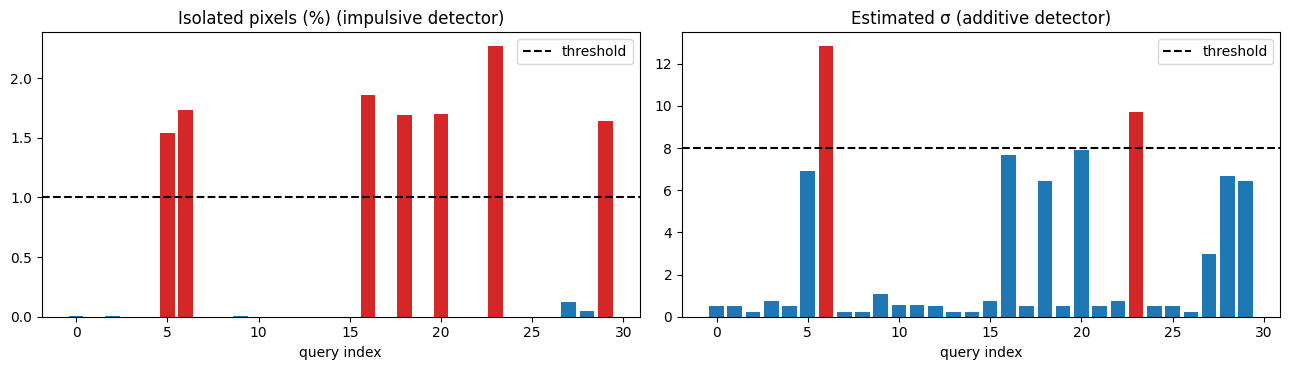

In [15]:
ISOLATED_THRESHOLD = 0.01 #fraction of isolated pixels
SIGMA_THRESHOLD = 8.0 #estimated noise std

qsd1_isolated = np.array([impulsive_noise(img) for img in qsd1_imgs])
qsd1_sigma = np.array([additive_noise(img) for img in qsd1_imgs])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, values, thr, title in [(axes[0], 100 * qsd1_isolated, 100 * ISOLATED_THRESHOLD, "Isolated pixels (%) (impulsive detector)"),
                               (axes[1], qsd1_sigma, SIGMA_THRESHOLD, "Estimated σ (additive detector)")]:
    ax.bar(range(len(values)), values, color=np.where(values > thr, "tab:red", "tab:blue"))
    ax.axhline(thr, ls="--", c="k", label="threshold")
    ax.set_xlabel("query index")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "task1_detector_scores.png"), dpi=120, bbox_inches="tight")
plt.show()

The images only contains impulsive noise, so no image should be classified as additive, and none is: the 23 clean images stay below the threshold, so there are no false alarms. Its ability to detect real additive noise could not be validated, since the dataset has no examples of it, so the threshold (σ = 8) is a fixed value chosen above the σ of clean images, not an optimised one.

Two images (00006 and 00023) exceed the σ threshold even though their noise is impulsive: impulses also increase the estimated σ. This is not an error, since these images are noisy anyway and both detectors simply agree. As the same filter is applied to any noisy image, it does not matter which detector flags it.

In [16]:
def is_noisy(img):
    if impulsive_noise(img) > ISOLATED_THRESHOLD:
        return True
    if additive_noise(img) > SIGMA_THRESHOLD:
        return True
    return False

qsd1_detected = np.array([is_noisy(img) for img in qsd1_imgs])
detected_idx = np.where(qsd1_detected)[0]
print("Detected as noisy:", [qsd1_files[i] for i in detected_idx])

#check with the real labels (only here, never used to decide)
tp = np.sum(qsd1_detected & qsd1_really_noisy)
fp = np.sum(qsd1_detected & ~qsd1_really_noisy)
fn = np.sum(~qsd1_detected & qsd1_really_noisy)
print(f"Correctly detected: {tp}/{qsd1_really_noisy.sum()}")
print(f"False positives: {fp}/{len(qsd1_really_noisy) - qsd1_really_noisy.sum()}")

Detected as noisy: ['00005.jpg', '00006.jpg', '00016.jpg', '00018.jpg', '00020.jpg', '00023.jpg', '00029.jpg']
Correctly detected: 7/7
False positives: 0/23


Now, we are ready to denoise the images detected as noisy. We will try several filters and compare their results. The best one will be used to denoise all the noisy images.

In [17]:
def ideal_lowpass(img, cutoff=0.5):
    h, w = img.shape[:2]
    fy = np.fft.fftshift(np.fft.fftfreq(h))[:, None]
    fx = np.fft.fftshift(np.fft.fftfreq(w))[None, :]
    H = (np.sqrt(fx ** 2 + fy ** 2) <= cutoff * 0.5).astype(np.float64)
    out = np.empty_like(img)
    for c in range(img.shape[2]):
        X = np.fft.fftshift(np.fft.fft2(img[..., c].astype(np.float64)))
        y = np.real(np.fft.ifft2(np.fft.ifftshift(X * H)))
        out[..., c] = np.clip(y, 0, 255)
    return out

SE = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3)) #3x3 square structuring element

def open_close(img, se=SE):
    #opening removes small bright points, then closing removes small dark points
    return cv2.morphologyEx(cv2.morphologyEx(img, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)

def close_open(img, se=SE):
    #closing removes small dark points, then opening removes small bright points
    return cv2.morphologyEx(cv2.morphologyEx(img, cv2.MORPH_CLOSE, se), cv2.MORPH_OPEN, se)

FILTERS = {
    #linear, spatial domain
    "average 3x3":         lambda img: cv2.blur(img, (3, 3)),
    "average 5x5":         lambda img: cv2.blur(img, (5, 5)),
    "gaussian 3x3":        lambda img: cv2.GaussianBlur(img, (3, 3), 0),
    "gaussian 5x5":        lambda img: cv2.GaussianBlur(img, (5, 5), 0),
    #linear, frequency domain
    "ideal low-pass 0.5":  lambda img: ideal_lowpass(img, 0.5),
    "ideal low-pass 0.3":  lambda img: ideal_lowpass(img, 0.3),
    #non-linear
    "median 3x3":          lambda img: cv2.medianBlur(img, 3),
    "median 5x5":          lambda img: cv2.medianBlur(img, 5),
    #morphological
    "open-close 3x3":      open_close,
    "close-open 3x3":      close_open,
}

def psnr(ref, img):
    mse = np.mean((ref.astype(np.float64) - img.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)

def ssim(ref, img):
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    blur = lambda z: cv2.GaussianBlur(z, (11, 11), 1.5)
    values = []
    for c in range(ref.shape[2]):
        x, y = ref[..., c].astype(np.float64), img[..., c].astype(np.float64)
        mu_x, mu_y = blur(x), blur(y)
        var_x = blur(x * x) - mu_x ** 2
        var_y = blur(y * y) - mu_y ** 2
        cov = blur(x * y) - mu_x * mu_y
        ssim_map = ((2 * mu_x * mu_y + C1) * (2 * cov + C2)) / ((mu_x ** 2 + mu_y ** 2 + C1) * (var_x + var_y + C2))
        values.append(ssim_map.mean())
    return np.mean(values)

#mean PSNR and SSIM of every filter on the images detected as noisy
def scores(filter_fn=None):
    out = [img if filter_fn is None else filter_fn(img) for img in (qsd1_imgs[i] for i in detected_idx)]
    ref = [qsd1_clean[i] for i in detected_idx]
    return np.mean([psnr(r, o) for r, o in zip(ref, out)]), np.mean([ssim(r, o) for r, o in zip(ref, out)])

rows = [dict(zip(["Filter", "PSNR (dB)", "SSIM"], ["no filter", *scores()]))]
for name, filter_fn in FILTERS.items():
    rows.append(dict(zip(["Filter", "PSNR (dB)", "SSIM"], [name, *scores(filter_fn)])))

df_psnr = pd.DataFrame(rows).sort_values("PSNR (dB)", ascending=False).reset_index(drop=True)
df_psnr.to_csv(os.path.join(results_dir, "task1_filters_psnr_ssim.csv"), index=False)
display(df_psnr.round(3))

BEST_FILTER = df_psnr.iloc[0]["Filter"]

,Filter,PSNR (dB),SSIM
0,median 3x3,30.778,0.797
1,median 5x5,30.271,0.771
2,gaussian 5x5,29.439,0.768
3,gaussian 3x3,29.116,0.740
4,average 3x3,29.046,0.738
5,average 5x5,28.474,0.723
6,ideal low-pass 0.5,28.276,0.689
7,ideal low-pass 0.3,28.264,0.705
8,open-close 3x3,27.366,0.742
9,close-open 3x3,26.086,0.722


The median 3x3 gives the best result in both PSNR and SSIM, as expected from the theory: it is a non-linear filter that discards outliers (impulses) instead of averaging them into the neighbours.

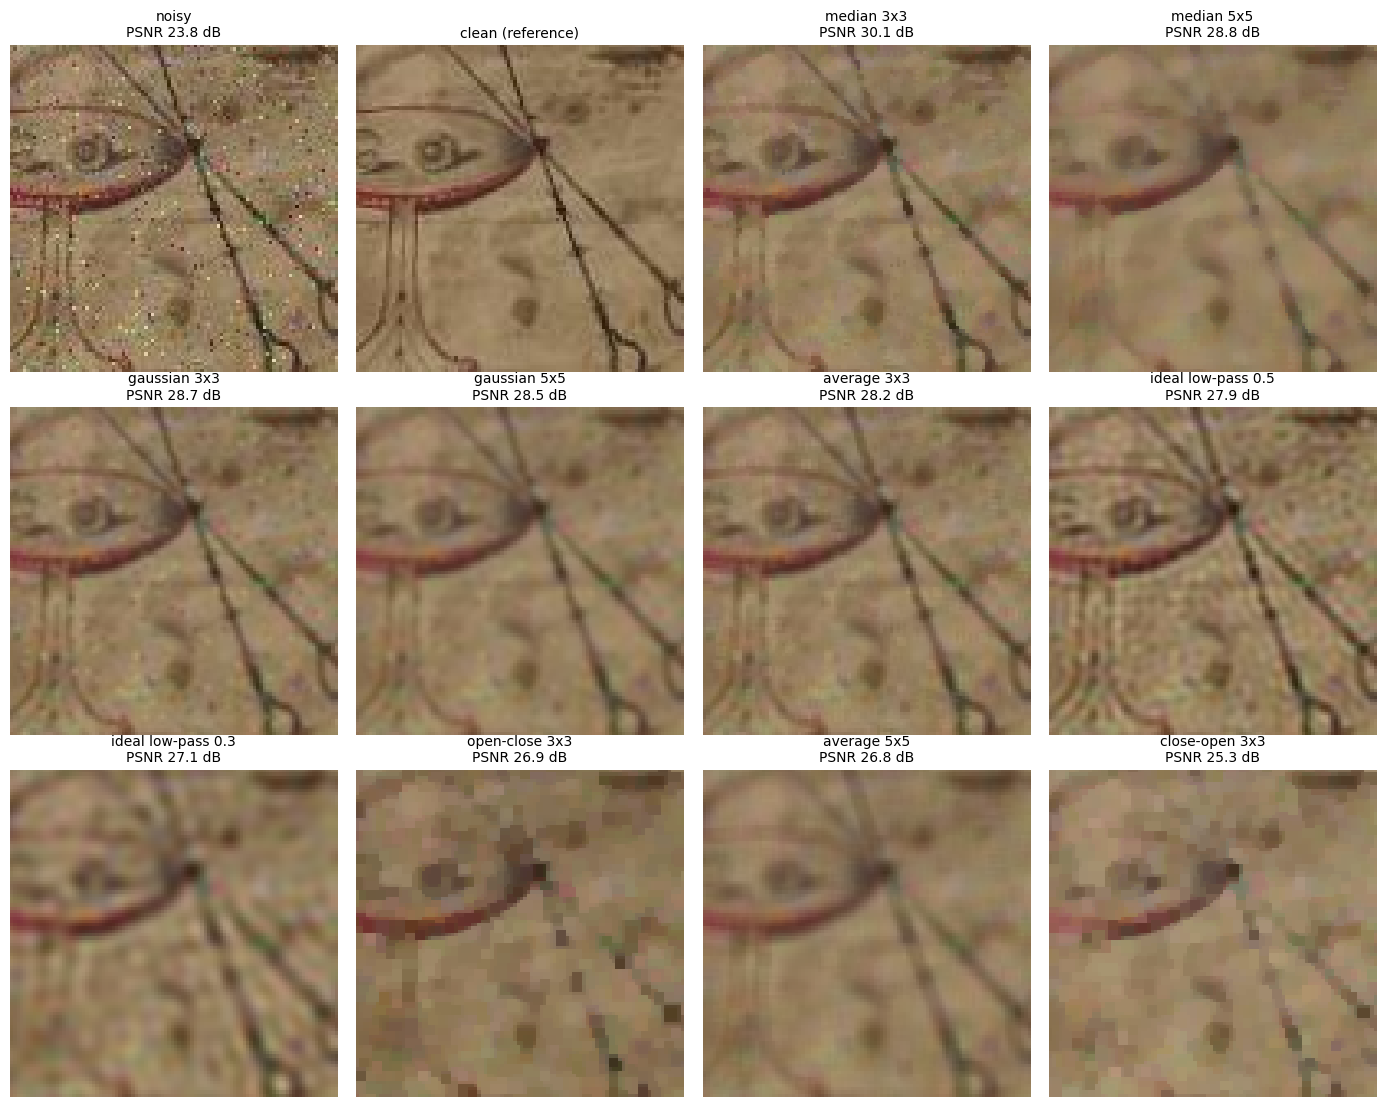

In [18]:
def zoom(img, size=100):
    h, w = img.shape[:2]
    y, x = h // 2 - size // 2, w // 2 - size // 2
    return img[y:y + size, x:x + size]

EXAMPLE = 4

i = detected_idx[EXAMPLE]
panels = [(name, f(qsd1_imgs[i])) for name, f in FILTERS.items()]
panels = [(name, im, psnr(qsd1_clean[i], im)) for name, im in panels]
panels.sort(key=lambda p: p[2], reverse=True)
panels = [("noisy", qsd1_imgs[i], psnr(qsd1_clean[i], qsd1_imgs[i])), ("clean (reference)", qsd1_clean[i], None)] + panels

n_cols = 4
n_rows = int(np.ceil(len(panels) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.5 * n_cols, 3.7 * n_rows))
for rank, (ax, (name, im, value)) in enumerate(zip(axes.flat, panels)):
    ax.imshow(cv2.cvtColor(zoom(im, 100), cv2.COLOR_BGR2RGB), interpolation="nearest")
    ax.set_title(name if value is None else f"{name}\nPSNR {value:.1f} dB", fontsize=10)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(results_dir, f"task1_all_filters_{qsd1_files[i][:-4]}.png"), dpi=120, bbox_inches="tight")
plt.show()

In [19]:
def denoise(img):
    return FILTERS[BEST_FILTER](img) if is_noisy(img) else img

qsd1_denoised = [denoise(img) for img in qsd1_imgs]

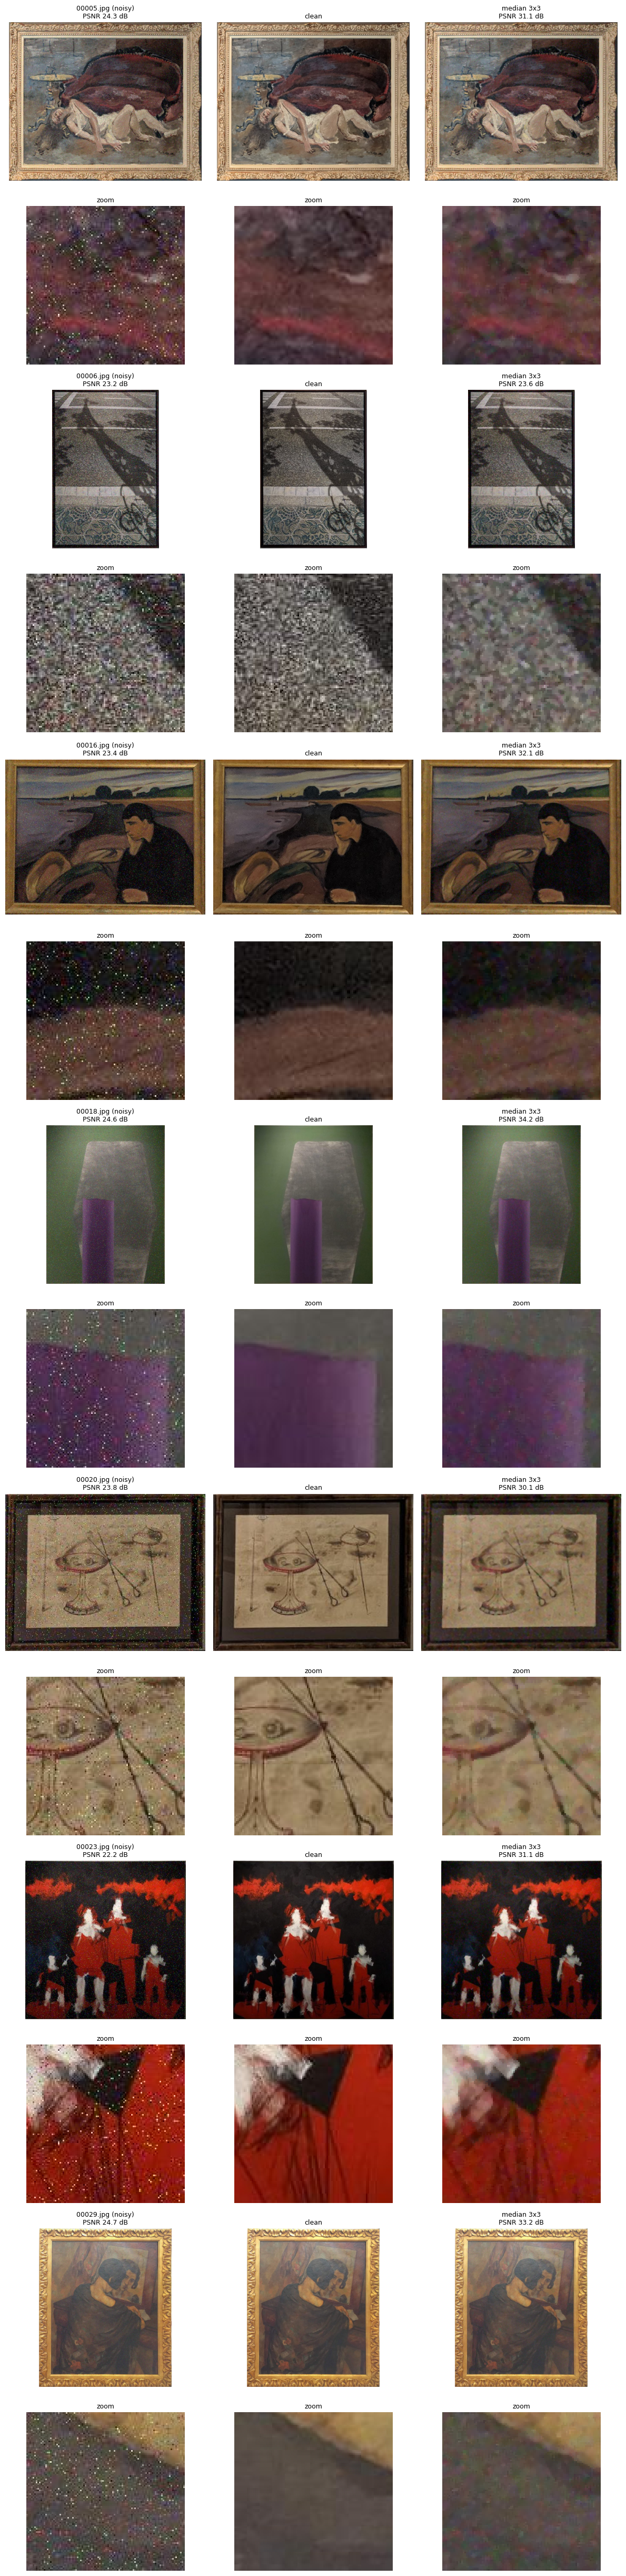

In [20]:
def show_results(indices, save_path=None):
    fig, axes = plt.subplots(2 * len(indices), 3, figsize=(12, 7 * len(indices)), squeeze=False)
    for k, i in enumerate(indices):
        top, bottom = 2 * k, 2 * k + 1
        panels = [(qsd1_imgs[i], f"{qsd1_files[i]} (noisy)\nPSNR {psnr(qsd1_clean[i], qsd1_imgs[i]):.1f} dB"),
                  (qsd1_clean[i], "clean"),
                  (qsd1_denoised[i], f"{BEST_FILTER}\nPSNR {psnr(qsd1_clean[i], qsd1_denoised[i]):.1f} dB")]
        for col, (im, title) in enumerate(panels):
            axes[top, col].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
            axes[top, col].set_title(title, fontsize=9)
            axes[bottom, col].imshow(cv2.cvtColor(zoom(im), cv2.COLOR_BGR2RGB), interpolation="nearest")
            axes[bottom, col].set_title("zoom", fontsize=9)
            axes[top, col].axis("off")
            axes[bottom, col].axis("off")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()

show_results(detected_idx, os.path.join(results_dir, "task1_results.png"))